# RealSense RGB 2D Part Detection Test

Run the code cell below to detect 3D printed parts in `realsense_pic/realsense_color_20260603_094805.png` using only RGB image processing. The script saves `detected_parts_result.png` and `detected_parts_2d.csv` in the current directory.


Detected 14 parts/candidates
01 | Gear_compound      center=(303.5, 389.5) area=19733.0 bbox=(222, 307, 165, 166) note=red HSV; lower large gear rule; equiv_diameter=158.5; circularity=0.66
02 | Gear_large         center=(412.5, 86.0) area=22672.5 bbox=(326, 0, 176, 176) note=red HSV; large equiv_diameter=169.9; circularity=0.65
03 | Gear_small         center=(139.5, 118.4) area=8175.5 bbox=(85, 65, 109, 108) note=red HSV; small equiv_diameter=102.0; circularity=0.66
04 | Screw              center=(301.5, 91.5) area=164.0 bbox=(290, 86, 24, 12) note=white candidate; compact small contour aspect=2.09
05 | Screw              center=(442.4, 214.5) area=140.0 bbox=(430, 204, 25, 16) note=white candidate; compact small contour aspect=1.57
06 | Screw              center=(90.5, 261.8) area=151.5 bbox=(82, 254, 20, 15) note=white candidate; compact small contour aspect=1.75
07 | Screw              center=(99.7, 320.1) area=279.0 bbox=(88, 310, 24, 19) note=white candidate; compact small contou

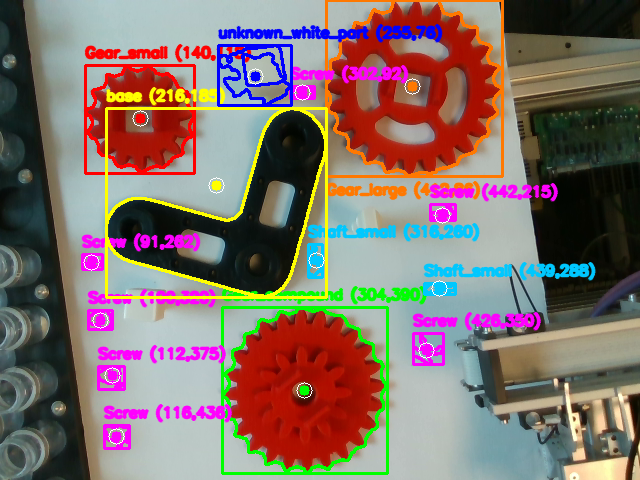

In [1]:
import csv
from pathlib import Path

import cv2
import numpy as np

try:
    from IPython.display import Image as IPyImage, display
except ImportError:
    IPyImage = None
    display = None


# =========================
# Easy-to-edit parameters
# =========================

IMAGE_PATH = "realsense_pic/realsense_color_20260603_094805.png"
RESULT_IMAGE_PATH = "detected_parts_result.png"
RESULT_CSV_PATH = "detected_parts_2d.csv"

# The white work table is tilted in the global RGB view. This polygon removes
# most left/right black background and right-side mechanical structure.
USE_MANUAL_WORK_AREA_POLYGON = True
WORK_AREA_POLYGON = np.array(
    [
        [70, 0],
        [520, 0],
        [455, 479],
        [78, 479],
    ],
    dtype=np.int32,
)
WORK_MASK_ERODE_KERNEL = 7

# HSV red segmentation. OpenCV HSV hue range is 0..179.
RED_HSV_LOWER_1 = np.array([0, 80, 50])
RED_HSV_UPPER_1 = np.array([12, 255, 255])
RED_HSV_LOWER_2 = np.array([165, 80, 50])
RED_HSV_UPPER_2 = np.array([179, 255, 255])
RED_OPEN_KERNEL = 3
RED_CLOSE_KERNEL = 9
GEAR_MIN_AREA = 1200
GEAR_MAX_AREA = 50000
GEAR_SMALL_MAX_EQUIV_DIAMETER = 115
GEAR_COMPOUND_MIN_EQUIV_DIAMETER = 120
GEAR_COMPOUND_MIN_CENTER_Y_RATIO = 0.56
GEAR_LARGE_MIN_EQUIV_DIAMETER = 115
GEAR_MIN_CIRCULARITY = 0.18

# Black base segmentation.
BLACK_HSV_LOWER = np.array([0, 0, 0])
BLACK_HSV_UPPER = np.array([179, 255, 85])
BLACK_OPEN_KERNEL = 5
BLACK_CLOSE_KERNEL = 13
BASE_MIN_AREA = 4500
BASE_MAX_AREA = 80000
BASE_MIN_BBOX_W = 80
BASE_MIN_BBOX_H = 60

# White/light small-part candidate detection. These parts are low contrast on
# the white table, so the defaults intentionally produce candidates that can be
# tuned later.
WHITE_PART_MIN_AREA = 120
WHITE_PART_MAX_AREA = 4500
WHITE_PART_MIN_W = 8
WHITE_PART_MIN_H = 8
WHITE_PART_MAX_W = 95
WHITE_PART_MAX_H = 95
WHITE_CANNY_LOW = 35
WHITE_CANNY_HIGH = 105
WHITE_ADAPTIVE_BLOCK_SIZE = 31
WHITE_ADAPTIVE_C = 4
WHITE_CLOSE_KERNEL = 5
WHITE_DILATE_KERNEL = 3
WHITE_EXCLUDE_RED_BLACK_DILATE = 27
WHITE_WORK_MASK_ERODE = 13

# Visualization colors are BGR because OpenCV uses BGR images.
DRAW_COLORS = {
    "base": (0, 255, 255),
    "Gear_small": (0, 0, 255),
    "Gear_large": (0, 120, 255),
    "Gear_compound": (0, 255, 0),
    "Screw": (255, 0, 255),
    "Shaft_large": (255, 128, 0),
    "Shaft_small": (255, 200, 0),
    "unknown_white_part": (255, 0, 0),
}


def load_image(image_path):
    """Read an RGB test image from disk. Returns an OpenCV BGR image."""
    path = Path(image_path)
    image = cv2.imread(str(path), cv2.IMREAD_COLOR)
    if image is None:
        raise FileNotFoundError(f"Could not read image: {path.resolve()}")
    return image


def create_work_area_mask(image):
    """Create a mask that keeps the white work table and removes side clutter."""
    h, w = image.shape[:2]
    mask = np.zeros((h, w), dtype=np.uint8)

    if USE_MANUAL_WORK_AREA_POLYGON:
        polygon = WORK_AREA_POLYGON.copy()
        polygon[:, 0] = np.clip(polygon[:, 0], 0, w - 1)
        polygon[:, 1] = np.clip(polygon[:, 1], 0, h - 1)
        cv2.fillPoly(mask, [polygon], 255)
    else:
        hsv = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)
        lab = cv2.cvtColor(image, cv2.COLOR_BGR2LAB)
        saturation = hsv[:, :, 1]
        value = hsv[:, :, 2]
        lightness = lab[:, :, 0]
        white_table = ((saturation < 80) & (value > 105) & (lightness > 115)).astype(np.uint8) * 255
        kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (21, 21))
        white_table = cv2.morphologyEx(white_table, cv2.MORPH_CLOSE, kernel, iterations=2)
        contours, _ = cv2.findContours(white_table, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        if contours:
            largest = max(contours, key=cv2.contourArea)
            cv2.drawContours(mask, [largest], -1, 255, thickness=cv2.FILLED)

    if WORK_MASK_ERODE_KERNEL > 1:
        kernel = cv2.getStructuringElement(
            cv2.MORPH_ELLIPSE, (WORK_MASK_ERODE_KERNEL, WORK_MASK_ERODE_KERNEL)
        )
        mask = cv2.erode(mask, kernel, iterations=1)
    return mask


def contour_center(contour):
    moments = cv2.moments(contour)
    if abs(moments["m00"]) > 1e-6:
        return moments["m10"] / moments["m00"], moments["m01"] / moments["m00"]
    x, y, w, h = cv2.boundingRect(contour)
    return x + w / 2.0, y + h / 2.0


def circularity(contour):
    area = cv2.contourArea(contour)
    perimeter = cv2.arcLength(contour, True)
    if perimeter <= 1e-6:
        return 0.0
    return 4.0 * np.pi * area / (perimeter * perimeter)


def make_detection(label, contour, note, center_mode="moments"):
    area = float(cv2.contourArea(contour))
    x, y, w, h = cv2.boundingRect(contour)
    if center_mode == "min_area_rect":
        (u, v), (rw, rh), angle = cv2.minAreaRect(contour)
        extra = {"rotated_angle": float(angle), "rect_w": float(rw), "rect_h": float(rh)}
    else:
        u, v = contour_center(contour)
        extra = {}
    return {
        "label": label,
        "center_u": float(u),
        "center_v": float(v),
        "area_px": area,
        "bbox_x": int(x),
        "bbox_y": int(y),
        "bbox_w": int(w),
        "bbox_h": int(h),
        "confidence_or_rule_note": note,
        "contour": contour,
        **extra,
    }


def detect_red_gears(image, work_mask):
    """Detect red gear contours and classify by size/location rules."""
    hsv = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)
    red_1 = cv2.inRange(hsv, RED_HSV_LOWER_1, RED_HSV_UPPER_1)
    red_2 = cv2.inRange(hsv, RED_HSV_LOWER_2, RED_HSV_UPPER_2)
    red_mask = cv2.bitwise_or(red_1, red_2)
    red_mask = cv2.bitwise_and(red_mask, work_mask)

    open_kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (RED_OPEN_KERNEL, RED_OPEN_KERNEL))
    close_kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (RED_CLOSE_KERNEL, RED_CLOSE_KERNEL))
    red_mask = cv2.morphologyEx(red_mask, cv2.MORPH_OPEN, open_kernel, iterations=1)
    red_mask = cv2.morphologyEx(red_mask, cv2.MORPH_CLOSE, close_kernel, iterations=2)

    contours, _ = cv2.findContours(red_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    detections = []
    image_h = image.shape[0]

    for contour in contours:
        area = cv2.contourArea(contour)
        if not (GEAR_MIN_AREA <= area <= GEAR_MAX_AREA):
            continue

        circ = circularity(contour)
        if circ < GEAR_MIN_CIRCULARITY:
            continue

        (u, v), radius = cv2.minEnclosingCircle(contour)
        equiv_diameter = 2.0 * np.sqrt(area / np.pi)
        x, y, w, h = cv2.boundingRect(contour)

        if equiv_diameter <= GEAR_SMALL_MAX_EQUIV_DIAMETER:
            label = "Gear_small"
            note = f"red HSV; small equiv_diameter={equiv_diameter:.1f}; circularity={circ:.2f}"
        elif v >= image_h * GEAR_COMPOUND_MIN_CENTER_Y_RATIO and equiv_diameter >= GEAR_COMPOUND_MIN_EQUIV_DIAMETER:
            label = "Gear_compound"
            note = f"red HSV; lower large gear rule; equiv_diameter={equiv_diameter:.1f}; circularity={circ:.2f}"
        elif equiv_diameter >= GEAR_LARGE_MIN_EQUIV_DIAMETER:
            label = "Gear_large"
            note = f"red HSV; large equiv_diameter={equiv_diameter:.1f}; circularity={circ:.2f}"
        else:
            label = "Gear_large"
            note = f"red HSV fallback; equiv_diameter={equiv_diameter:.1f}; circularity={circ:.2f}"

        det = make_detection(label, contour, note)
        det["center_u"] = float(u)
        det["center_v"] = float(v)
        det["equivalent_diameter"] = float(equiv_diameter)
        det["enclosing_radius"] = float(radius)
        det["bbox_x"], det["bbox_y"], det["bbox_w"], det["bbox_h"] = int(x), int(y), int(w), int(h)
        detections.append(det)

    return sorted(detections, key=lambda d: (d["bbox_y"], d["bbox_x"]))


def detect_black_base(image, work_mask):
    """Detect the largest black base contour inside the work area."""
    hsv = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)
    black_mask = cv2.inRange(hsv, BLACK_HSV_LOWER, BLACK_HSV_UPPER)
    black_mask = cv2.bitwise_and(black_mask, work_mask)

    open_kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (BLACK_OPEN_KERNEL, BLACK_OPEN_KERNEL))
    close_kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (BLACK_CLOSE_KERNEL, BLACK_CLOSE_KERNEL))
    black_mask = cv2.morphologyEx(black_mask, cv2.MORPH_OPEN, open_kernel, iterations=1)
    black_mask = cv2.morphologyEx(black_mask, cv2.MORPH_CLOSE, close_kernel, iterations=2)

    contours, _ = cv2.findContours(black_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    candidates = []
    for contour in contours:
        area = cv2.contourArea(contour)
        x, y, w, h = cv2.boundingRect(contour)
        if not (BASE_MIN_AREA <= area <= BASE_MAX_AREA):
            continue
        if w < BASE_MIN_BBOX_W or h < BASE_MIN_BBOX_H:
            continue
        candidates.append(contour)

    if not candidates:
        return []

    base_contour = max(candidates, key=cv2.contourArea)
    det = make_detection(
        "base",
        base_contour,
        "black HSV; largest valid contour in work area",
        center_mode="min_area_rect",
    )
    det["confidence_or_rule_note"] += f"; angle={det.get('rotated_angle', 0.0):.1f}"
    return [det]


def detect_white_parts(image, work_mask):
    """Detect white/light small-part candidates using edges and local contrast."""
    hsv = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

    red_1 = cv2.inRange(hsv, RED_HSV_LOWER_1, RED_HSV_UPPER_1)
    red_2 = cv2.inRange(hsv, RED_HSV_LOWER_2, RED_HSV_UPPER_2)
    red_mask = cv2.bitwise_or(red_1, red_2)
    black_mask = cv2.inRange(hsv, BLACK_HSV_LOWER, BLACK_HSV_UPPER)
    colored_or_black = cv2.bitwise_or(red_mask, black_mask)

    clahe = cv2.createCLAHE(clipLimit=2.2, tileGridSize=(8, 8))
    enhanced = clahe.apply(gray)
    blurred = cv2.GaussianBlur(enhanced, (5, 5), 0)
    edges = cv2.Canny(blurred, WHITE_CANNY_LOW, WHITE_CANNY_HIGH)

    block_size = WHITE_ADAPTIVE_BLOCK_SIZE
    if block_size % 2 == 0:
        block_size += 1
    adaptive = cv2.adaptiveThreshold(
        blurred,
        255,
        cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
        cv2.THRESH_BINARY_INV,
        block_size,
        WHITE_ADAPTIVE_C,
    )

    candidate_mask = cv2.bitwise_or(edges, adaptive)

    white_work_mask = work_mask.copy()
    if WHITE_WORK_MASK_ERODE > 1:
        work_kernel = cv2.getStructuringElement(
            cv2.MORPH_ELLIPSE, (WHITE_WORK_MASK_ERODE, WHITE_WORK_MASK_ERODE)
        )
        white_work_mask = cv2.erode(white_work_mask, work_kernel, iterations=1)

    exclude_mask = colored_or_black.copy()
    if WHITE_EXCLUDE_RED_BLACK_DILATE > 1:
        exclude_kernel = cv2.getStructuringElement(
            cv2.MORPH_ELLIPSE, (WHITE_EXCLUDE_RED_BLACK_DILATE, WHITE_EXCLUDE_RED_BLACK_DILATE)
        )
        exclude_mask = cv2.dilate(exclude_mask, exclude_kernel, iterations=1)

    candidate_mask = cv2.bitwise_and(candidate_mask, white_work_mask)
    candidate_mask[exclude_mask > 0] = 0

    close_kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (WHITE_CLOSE_KERNEL, WHITE_CLOSE_KERNEL))
    dilate_kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (WHITE_DILATE_KERNEL, WHITE_DILATE_KERNEL))
    candidate_mask = cv2.morphologyEx(candidate_mask, cv2.MORPH_CLOSE, close_kernel, iterations=1)
    candidate_mask = cv2.dilate(candidate_mask, dilate_kernel, iterations=1)

    contours, _ = cv2.findContours(candidate_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    detections = []
    for contour in contours:
        area = cv2.contourArea(contour)
        x, y, w, h = cv2.boundingRect(contour)
        if not (WHITE_PART_MIN_AREA <= area <= WHITE_PART_MAX_AREA):
            continue
        if not (WHITE_PART_MIN_W <= w <= WHITE_PART_MAX_W and WHITE_PART_MIN_H <= h <= WHITE_PART_MAX_H):
            continue

        rect = cv2.minAreaRect(contour)
        (_, _), (rw, rh), angle = rect
        long_side = max(rw, rh)
        short_side = max(1.0, min(rw, rh))
        aspect = long_side / short_side

        # Reject very thin edge fragments that survive the red/black exclusion.
        if short_side < 5 and area < 300:
            continue

        if aspect >= 2.7 and long_side >= 45:
            label = "Shaft_large"
            note = f"white candidate; elongated large aspect={aspect:.2f}; angle={angle:.1f}"
        elif aspect >= 2.2 and long_side >= 24:
            label = "Shaft_small"
            note = f"white candidate; elongated small aspect={aspect:.2f}; angle={angle:.1f}"
        elif area <= 900 and max(w, h) <= 42:
            label = "Screw"
            note = f"white candidate; compact small contour aspect={aspect:.2f}"
        else:
            label = "unknown_white_part"
            note = f"white candidate; weak contrast fallback aspect={aspect:.2f}"

        detections.append(make_detection(label, contour, note, center_mode="min_area_rect"))

    return sorted(detections, key=lambda d: (d["bbox_y"], d["bbox_x"]))


def draw_detections(image, detections):
    """Draw contours, bounding boxes, labels, and 2D centers on an image."""
    output = image.copy()
    for det in detections:
        label = det["label"]
        color = DRAW_COLORS.get(label, (255, 255, 255))
        x, y, w, h = det["bbox_x"], det["bbox_y"], det["bbox_w"], det["bbox_h"]
        u, v = int(round(det["center_u"])), int(round(det["center_v"]))

        contour = det.get("contour")
        if contour is not None:
            cv2.drawContours(output, [contour], -1, color, 2)
        cv2.rectangle(output, (x, y), (x + w, y + h), color, 2)
        cv2.circle(output, (u, v), 5, color, thickness=-1)
        cv2.circle(output, (u, v), 8, (255, 255, 255), thickness=1)

        text = f"{label} ({u},{v})"
        text_y = y - 8 if y > 18 else y + h + 18
        cv2.putText(output, text, (x, text_y), cv2.FONT_HERSHEY_SIMPLEX, 0.48, color, 2, cv2.LINE_AA)
    return output


def save_results_csv(detections, csv_path):
    """Save detection results without contour arrays to CSV."""
    fieldnames = [
        "label",
        "center_u",
        "center_v",
        "area_px",
        "bbox_x",
        "bbox_y",
        "bbox_w",
        "bbox_h",
        "confidence_or_rule_note",
    ]
    with open(csv_path, "w", newline="", encoding="utf-8") as f:
        writer = csv.DictWriter(f, fieldnames=fieldnames)
        writer.writeheader()
        for det in detections:
            row = {name: det.get(name, "") for name in fieldnames}
            row["center_u"] = round(float(row["center_u"]), 2)
            row["center_v"] = round(float(row["center_v"]), 2)
            row["area_px"] = round(float(row["area_px"]), 1)
            writer.writerow(row)


def print_detections(detections):
    print(f"Detected {len(detections)} parts/candidates")
    for i, det in enumerate(detections, start=1):
        print(
            f"{i:02d} | {det['label']:<18} "
            f"center=({det['center_u']:.1f}, {det['center_v']:.1f}) "
            f"area={det['area_px']:.1f} "
            f"bbox=({det['bbox_x']}, {det['bbox_y']}, {det['bbox_w']}, {det['bbox_h']}) "
            f"note={det['confidence_or_rule_note']}"
        )


def main():
    image = load_image(IMAGE_PATH)
    work_mask = create_work_area_mask(image)

    detections = []
    detections.extend(detect_red_gears(image, work_mask))
    detections.extend(detect_black_base(image, work_mask))
    detections.extend(detect_white_parts(image, work_mask))
    detections = sorted(detections, key=lambda d: (d["label"], d["bbox_y"], d["bbox_x"]))

    result_image = draw_detections(image, detections)
    cv2.imwrite(RESULT_IMAGE_PATH, result_image)
    save_results_csv(detections, RESULT_CSV_PATH)
    print_detections(detections)
    print(f"\nSaved result image: {Path(RESULT_IMAGE_PATH).resolve()}")
    print(f"Saved CSV: {Path(RESULT_CSV_PATH).resolve()}")

    if display is not None and IPyImage is not None:
        display(IPyImage(filename=RESULT_IMAGE_PATH))


main()
